In [2]:
import pandas
import numpy
import matplotlib
import seaborn
import sklearn
import joblib
import streamlit

print("All required libraries are available!")

All required libraries are available!


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, confusion_matrix

import joblib

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
df = pd.read_csv("Salary Data.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (375, 6)


In [5]:
df

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0
...,...,...,...,...,...,...
370,35.0,Female,Bachelor's,Senior Marketing Analyst,8.0,85000.0
371,43.0,Male,Master's,Director of Operations,19.0,170000.0
372,29.0,Female,Bachelor's,Junior Project Manager,2.0,40000.0
373,34.0,Male,Bachelor's,Senior Operations Coordinator,7.0,90000.0


In [6]:
df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


In [7]:
print(df.columns.tolist())

['Age', 'Gender', 'Education Level', 'Job Title', 'Years of Experience', 'Salary']


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 375 entries, 0 to 374
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  373 non-null    float64
 1   Gender               373 non-null    str    
 2   Education Level      373 non-null    str    
 3   Job Title            373 non-null    str    
 4   Years of Experience  373 non-null    float64
 5   Salary               373 non-null    float64
dtypes: float64(3), str(3)
memory usage: 30.8 KB


In [9]:
df.isnull().sum()

Age                    2
Gender                 2
Education Level        2
Job Title              2
Years of Experience    2
Salary                 2
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(50)

In [11]:
df["Salary"] = pd.to_numeric(df["Salary"], errors="coerce")

print(df["Salary"].dtype)
print(df["Salary"].isnull().sum())

float64
2


In [12]:
df["Gender"] = df["Gender"].astype(str).str.strip()
df["Education Level"] = df["Education Level"].astype(str).str.strip()
df["Job Title"] = df["Job Title"].astype(str).str.strip()

print("Categorical columns cleaned successfully!")

Categorical columns cleaned successfully!


In [13]:
df = df.dropna(subset=[
    "Age",
    "Gender",
    "Education Level",
    "Job Title",
    "Years of Experience",
    "Salary"
])

print("Missing values removed!")
print("New shape:", df.shape)

Missing values removed!
New shape: (373, 6)


In [14]:
print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (373, 6)

Missing values:
Age                    0
Gender                 0
Education Level        0
Job Title              0
Years of Experience    0
Salary                 0
dtype: int64


In [15]:
df["Salary"].describe()

count       373.000000
mean     100577.345845
std       48240.013482
min         350.000000
25%       55000.000000
50%       95000.000000
75%      140000.000000
max      250000.000000
Name: Salary, dtype: float64

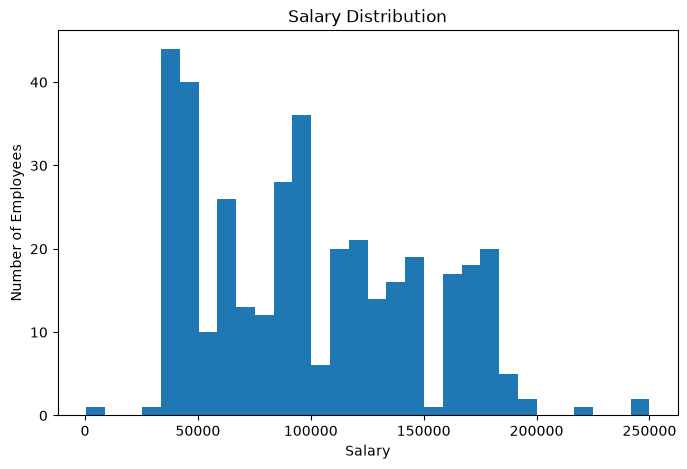

In [16]:
plt.figure(figsize=(8, 5))

plt.hist(df["Salary"], bins=30)

plt.xlabel("Salary")
plt.ylabel("Number of Employees")
plt.title("Salary Distribution")

plt.show()

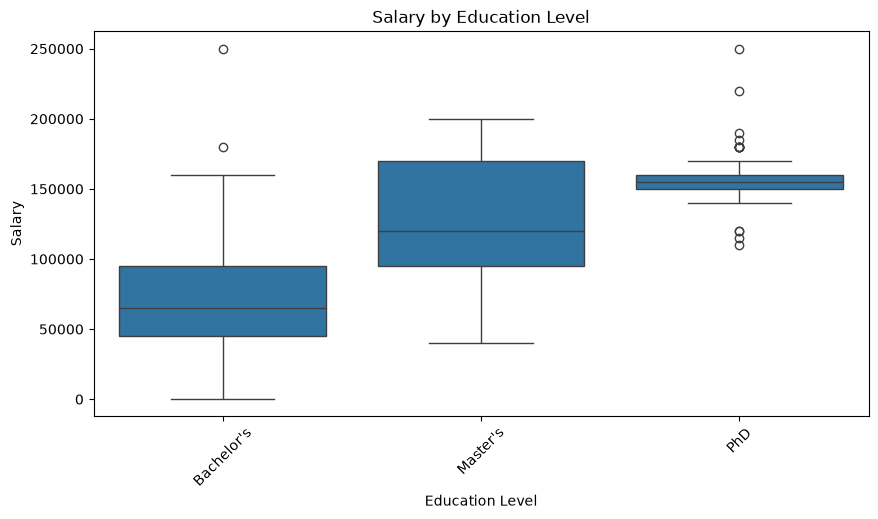

In [17]:
plt.figure(figsize=(10, 5))

sns.boxplot(x="Education Level", y="Salary", data=df)

plt.xlabel("Education Level")
plt.ylabel("Salary")
plt.title("Salary by Education Level")

plt.xticks(rotation=45)
plt.show()

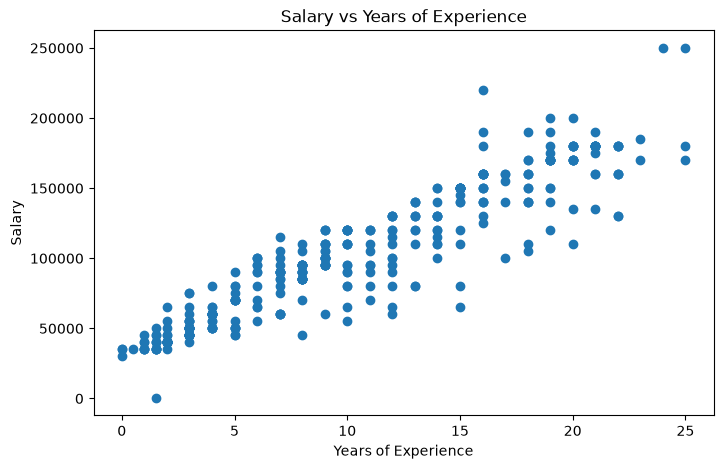

In [18]:
plt.figure(figsize=(8, 5))

plt.scatter(df["Years of Experience"], df["Salary"])

plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Salary vs Years of Experience")

plt.show()

In [19]:
X = df[[
    "Age",
    "Gender",
    "Education Level",
    "Job Title",
    "Years of Experience"
]].copy()

y = df["Salary"].copy()

print("Features (X):")
print(X.head())

print("\nTarget (y):")
print(y.head())

Features (X):
    Age  Gender Education Level          Job Title  Years of Experience
0  32.0    Male      Bachelor's  Software Engineer                  5.0
1  28.0  Female        Master's       Data Analyst                  3.0
2  45.0    Male             PhD     Senior Manager                 15.0
3  36.0  Female      Bachelor's    Sales Associate                  7.0
4  52.0    Male        Master's           Director                 20.0

Target (y):
0     90000.0
1     65000.0
2    150000.0
3     60000.0
4    200000.0
Name: Salary, dtype: float64


In [20]:
gender_encoder = LabelEncoder()
education_encoder = LabelEncoder()
job_encoder = LabelEncoder()

X["Gender"] = gender_encoder.fit_transform(X["Gender"])
X["Education Level"] = education_encoder.fit_transform(X["Education Level"])
X["Job Title"] = job_encoder.fit_transform(X["Job Title"])

print("Categorical columns encoded successfully!")
print(X.head())

Categorical columns encoded successfully!
    Age  Gender  Education Level  Job Title  Years of Experience
0  32.0       1                0        159                  5.0
1  28.0       0                1         17                  3.0
2  45.0       1                2        130                 15.0
3  36.0       0                0        101                  7.0
4  52.0       1                1         22                 20.0


In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (298, 5)
Testing data: (75, 5)


In [24]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [25]:
y_pred = linear_model.predict(X_test)

print("Predicted Salaries:")
print(y_pred[:10])

Predicted Salaries:
[167633.68695158  93362.33215371 130879.62380038  84293.36442107
 161044.59433795 159610.94787507 157000.39505879 104784.30551165
  57465.48625109 101175.03451504]


In [26]:
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

print("Linear Regression Evaluation")
print("R² Score:", r2)
print("Mean Squared Error:", mse)

Linear Regression Evaluation
R² Score: 0.8961138207821872
Mean Squared Error: 249075656.4272197


In [27]:
median_salary = df["Salary"].median()

df["Salary_Category"] = np.where(
    df["Salary"] >= median_salary,
    1,
    0
)

print("Median Salary:", median_salary)
print("\nSalary Category:")
print(df["Salary_Category"].value_counts())

Median Salary: 95000.0

Salary Category:
Salary_Category
1    198
0    175
Name: count, dtype: int64


In [28]:
X_log = X.copy()
y_log = df["Salary_Category"].copy()

print("Logistic Regression features:")
print(X_log.head())

print("\nTarget:")
print(y_log.head())

Logistic Regression features:
    Age  Gender  Education Level  Job Title  Years of Experience
0  32.0       1                0        159                  5.0
1  28.0       0                1         17                  3.0
2  45.0       1                2        130                 15.0
3  36.0       0                0        101                  7.0
4  52.0       1                1         22                 20.0

Target:
0    0
1    0
2    1
3    0
4    1
Name: Salary_Category, dtype: int64


In [29]:
X_train_log, X_test_log, y_train_log, y_test_log = train_test_split(
    X_log,
    y_log,
    test_size=0.2,
    random_state=42
)

print("Logistic Regression training data:", X_train_log.shape)
print("Logistic Regression testing data:", X_test_log.shape)

Logistic Regression training data: (298, 5)
Logistic Regression testing data: (75, 5)


In [30]:
logistic_model = LogisticRegression(max_iter=1000)

logistic_model.fit(X_train_log, y_train_log)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [31]:
y_pred_log = logistic_model.predict(X_test_log)

print("Predicted Salary Categories:")
print(y_pred_log[:10])

Predicted Salary Categories:
[1 0 1 0 1 1 1 1 0 1]


In [32]:
accuracy = accuracy_score(y_test_log, y_pred_log)

print("Logistic Regression Evaluation")
print("Accuracy:", accuracy)

Logistic Regression Evaluation
Accuracy: 0.92


In [33]:
cm = confusion_matrix(y_test_log, y_pred_log)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[31  1]
 [ 5 38]]


In [34]:
joblib.dump(linear_model, "salary_linear_model.pkl")
joblib.dump(logistic_model, "salary_logistic_model.pkl")

joblib.dump(gender_encoder, "gender_encoder.pkl")
joblib.dump(education_encoder, "education_encoder.pkl")
joblib.dump(job_encoder, "job_encoder.pkl")

print("All models and encoders saved successfully!")

All models and encoders saved successfully!


In [35]:
df.to_csv("salary_processed.csv", index=False)

print("Processed dataset saved successfully!")

Processed dataset saved successfully!


In [36]:
import os

files = [
    "salary_linear_model.pkl",
    "salary_logistic_model.pkl",
    "gender_encoder.pkl",
    "education_encoder.pkl",
    "job_encoder.pkl",
    "salary_processed.csv"
]

for file in files:
    print(file, "→", "Found ✅" if os.path.exists(file) else "Missing ❌")

salary_linear_model.pkl → Found ✅
salary_logistic_model.pkl → Found ✅
gender_encoder.pkl → Found ✅
education_encoder.pkl → Found ✅
job_encoder.pkl → Found ✅
salary_processed.csv → Found ✅


In [39]:
%%writefile app.py

import streamlit as st
import pandas as pd
import joblib


# =========================================================
# PAGE CONFIGURATION
# =========================================================

st.set_page_config(
    page_title="Salary Prediction System",
    page_icon="💰",
    layout="wide"
)


# =========================================================
# DARK PURPLE THEME + WHITE FONT
# =========================================================

st.markdown("""
<style>

/* Main application background */
.stApp {
    background-color: #0f0718;
    color: white;
}


/* Sidebar background */
[data-testid="stSidebar"] {
    background-color: #241033;
}


/* Sidebar text */
[data-testid="stSidebar"] * {
    color: white !important;
}


/* All headings */
h1, h2, h3, h4, h5, h6 {
    color: white !important;
}


/* Normal text */
p, span, div, label {
    color: white !important;
}


/* Input labels */
.stTextInput label,
.stNumberInput label,
.stSelectbox label,
.stRadio label,
.stSlider label {
    color: white !important;
}


/* Number input text */
input {
    color: black !important;
}


/* Selectbox text */
[data-baseweb="select"] * {
    color: black !important;
}


/* Selectbox dropdown */
[data-baseweb="popover"] * {
    color: black !important;
}


/* Radio buttons */
[data-testid="stRadio"] label {
    color: white !important;
}


/* Button */
.stButton > button {
    background-color: #7b2cbf;
    color: white !important;
    border: none;
    border-radius: 8px;
    padding: 10px 20px;
    font-weight: bold;
}


/* Button hover */
.stButton > button:hover {
    background-color: #9d4edd;
    color: white !important;
}


/* Metric boxes */
[data-testid="stMetric"] {
    background-color: #241033;
    padding: 15px;
    border-radius: 10px;
}


/* Metric labels */
[data-testid="stMetricLabel"] {
    color: white !important;
}


/* Metric values */
[data-testid="stMetricValue"] {
    color: white !important;
}


/* Captions */
.stCaption {
    color: white !important;
}


/* Markdown text */
.stMarkdown {
    color: white !important;
}


/* Horizontal line */
hr {
    border-color: #4c1d75 !important;
}


/* Success message */
[data-testid="stAlert"] {
    color: white !important;
}


/* Sidebar radio selected item */
[data-testid="stSidebar"] [data-testid="stRadio"] label {
    color: white !important;
}

</style>
""", unsafe_allow_html=True)


# =========================================================
# LOAD DATA
# =========================================================

@st.cache_data
def load_data():

    data = pd.read_csv("Salary Data.csv")

    return data


df = load_data()


# =========================================================
# LOAD MODELS AND ENCODERS
# =========================================================

linear_model = joblib.load(
    "salary_linear_model.pkl"
)

logistic_model = joblib.load(
    "salary_logistic_model.pkl"
)

gender_encoder = joblib.load(
    "gender_encoder.pkl"
)

education_encoder = joblib.load(
    "education_encoder.pkl"
)

job_encoder = joblib.load(
    "job_encoder.pkl"
)


# =========================================================
# SIDEBAR
# =========================================================

st.sidebar.title("💰 Salary Prediction")

st.sidebar.markdown(
    "### Navigation"
)

page = st.sidebar.radio(
    "",
    [
        "Salary Predictor",
        "Analytics Dashboard"
    ]
)


# =========================================================
# SALARY PREDICTOR
# =========================================================

if page == "Salary Predictor":

    st.title("💰 Salary Prediction System")

    st.write(
        "Predict salary using Linear Regression and "
        "classify salary using Logistic Regression."
    )

    st.markdown("---")


    # =====================================================
    # INPUT SECTION
    # =====================================================

    col1, col2 = st.columns(2)


    # -----------------------------------------------------
    # LEFT COLUMN
    # -----------------------------------------------------

    with col1:

        age = st.number_input(
            "Age",
            min_value=18,
            max_value=70,
            value=30
        )


        gender = st.selectbox(
            "Gender",
            gender_encoder.classes_
        )


        education = st.selectbox(
            "Education Level",
            education_encoder.classes_
        )


    # -----------------------------------------------------
    # RIGHT COLUMN
    # -----------------------------------------------------

    with col2:

        experience = st.number_input(
            "Years of Experience",
            min_value=0.0,
            max_value=50.0,
            value=5.0,
            step=0.5
        )


        job_title = st.selectbox(
            "Job Title",
            job_encoder.classes_
        )


    st.markdown("---")


    # =====================================================
    # MODEL SELECTION
    # =====================================================

    st.subheader("Choose Prediction Type")


    model_type = st.radio(
        "",
        [
            "Linear Regression",
            "Logistic Regression"
        ],
        horizontal=True
    )


    st.markdown("")


    # =====================================================
    # PREDICT BUTTON
    # =====================================================

    predict_button = st.button(
        "🔮 PREDICT SALARY"
    )


    # =====================================================
    # PREDICTION
    # =====================================================

    if predict_button:


        # -------------------------------------------------
        # Encode user inputs
        # -------------------------------------------------

        gender_value = gender_encoder.transform(
            [gender]
        )[0]


        education_value = education_encoder.transform(
            [education]
        )[0]


        job_value = job_encoder.transform(
            [job_title]
        )[0]


        # -------------------------------------------------
        # Create input DataFrame
        # -------------------------------------------------

        input_data = pd.DataFrame({

            "Age": [age],

            "Gender": [gender_value],

            "Education Level": [education_value],

            "Job Title": [job_value],

            "Years of Experience": [experience]

        })


        # =================================================
        # LINEAR REGRESSION
        # =================================================

        if model_type == "Linear Regression":


            prediction = linear_model.predict(
                input_data
            )[0]


            st.success(
                f"💰 Predicted Salary: ₹{prediction:,.2f}"
            )


        # =================================================
        # LOGISTIC REGRESSION
        # =================================================

        else:


            prediction = logistic_model.predict(
                input_data
            )[0]


            probability = logistic_model.predict_proba(
                input_data
            )[0]


            if prediction == 1:

                st.success(
                    "🟢 Salary Category: HIGH"
                )

                st.write(
                    f"Probability of High Salary: "
                    f"{probability[1] * 100:.2f}%"
                )


            else:

                st.warning(
                    "🟡 Salary Category: LOW"
                )

                st.write(
                    f"Probability of Low Salary: "
                    f"{probability[0] * 100:.2f}%"
                )


# =========================================================
# ANALYTICS DASHBOARD
# =========================================================

else:


    st.title(
        "📊 Salary Analytics Dashboard"
    )


    st.write(
        "Explore salary patterns in the dataset."
    )


    st.markdown("---")


    # =====================================================
    # METRICS
    # =====================================================

    col1, col2, col3, col4 = st.columns(4)


    with col1:

        st.metric(
            "Employees",
            len(df)
        )


    with col2:

        st.metric(
            "Average Salary",
            f"₹{df['Salary'].mean():,.0f}"
        )


    with col3:

        st.metric(
            "Minimum Salary",
            f"₹{df['Salary'].min():,.0f}"
        )


    with col4:

        st.metric(
            "Maximum Salary",
            f"₹{df['Salary'].max():,.0f}"
        )


    st.markdown("---")


    # =====================================================
    # SALARY DISTRIBUTION
    # =====================================================

    st.subheader(
        "📈 Salary Distribution"
    )


    salary_distribution = (
        df["Salary"]
        .value_counts()
        .sort_index()
    )


    st.bar_chart(
        salary_distribution
    )


    # =====================================================
    # SALARY BY EDUCATION
    # =====================================================

    st.subheader(
        "🎓 Salary by Education Level"
    )


    education_salary = (
        df.groupby("Education Level")["Salary"]
        .mean()
        .sort_values()
    )


    st.bar_chart(
        education_salary
    )


    # =====================================================
    # EXPERIENCE VS SALARY
    # =====================================================

    st.subheader(
        "💼 Experience vs Salary"
    )


    experience_salary = (
        df.groupby("Years of Experience")["Salary"]
        .mean()
        .sort_index()
    )


    st.line_chart(
        experience_salary
    )


# =========================================================
# FOOTER
# =========================================================

st.markdown("---")

st.caption(
    "Created by Pradeepa Viswanathan | "
    "Salary Prediction Project"
)

Overwriting app.py


In [ ]:
!python -m streamlit run app.py